# Práctica 1 – Ingeniería del Conocimiento: Fase 3: Ingeniería de variables y comparación de modelos

Este cuaderno continúa la Fase 2 (preprocesado). Se usan las mismas particiones congeladas (KFold aleatorio 5x3, semilla 42) y el mismo criterio: una variante solo **mejora** si |media de la diferencia de RMSE| > su desviación entre los 15 folds.

| Apartado de la memoria | Sección del cuaderno |
|---|---|
| 3.1 Forma del efecto del peso | F3.1 |
| 3.2 Ingeniería de variables en el modelo lineal sobre log(precio) | F3.2 |
| 3.3 Comparación de modelos | F3.3 |
| Figuras 11 y 12 | F3.1 y F3.4 |

In [1]:
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold, KFold, ParameterSampler

SEED = 42

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | scipy 1.16.3 | matplotlib 3.10.0


## 0 Carga de datos
Se leen `train-1.csv` y `test-1.csv` de la misma carpeta que el cuaderno.

In [2]:
RUTA_DATOS = ''   # carpeta de los CSV; '' = misma carpeta que el cuaderno
tr = pd.read_csv(RUTA_DATOS + 'train-1.csv')
te = pd.read_csv(RUTA_DATOS + 'test-1.csv')

X = tr.drop(columns=['id', 'price']).copy()
y = tr['price'].to_numpy(dtype=float)
X_test = te.drop(columns=['id']).copy()
print('X:', X.shape, '| X_test:', X_test.shape)

X: (8000, 14) | X_test: (2000, 14)


## Definiciones: variables, modelos, corrección de Duan, validación cruzada y tablas

In [3]:
UMBRAL = 300   # tramo de precio para el desglose del error: <= 300 € y > 300 €

# Preprocesado decidido en la Fase 2: fuera material, brand_tier, is_promo y country
CAT_SEL = ['category', 'brand', 'season', 'channel']
NUMS = ['peso', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount']


def variables(df, peso='crudo', log_reviews=False):
    """Variables del modelo. Las transformaciones son fila a fila (no aprenden nada de los datos),
    así que se pueden calcular antes de la CV sin fuga de información.
    peso: 'crudo' (weight_kg), 'log' (log(weight_kg)) o 'log1p' (log(1 + weight_kg))."""
    out = df[CAT_SEL].astype(str).copy()
    out['peso'] = {'crudo': df.weight_kg, 'log': np.log(df.weight_kg), 'log1p': np.log1p(df.weight_kg)}[peso]
    out['rating'] = df.rating
    out['reviews'] = np.log1p(df.reviews) if log_reviews else df.reviews
    out['shipping_cost'] = df.shipping_cost
    out['margin'] = df.margin
    out['discount'] = df.discount
    return out


def lineal(splines=False, n_knots=5, alpha=None):
    """Modelo lineal: one-hot (drop='first') + numéricas estandarizadas [+ splines cúbicas de las numéricas].
    Con splines se usa Ridge, porque las splines y los términos lineales son colineales."""
    tf = [('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT_SEL),
          ('num', StandardScaler(), NUMS)]
    if splines:
        tf.append(('spl', SplineTransformer(n_knots=n_knots, degree=3), NUMS))
    reg = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return Pipeline([('prep', ColumnTransformer(tf)), ('model', reg)])


def arboles(modelo, **params):
    """Modelos de árboles: one-hot sin drop + numéricas sin escalar."""
    prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_SEL),
                              ('num', 'passthrough', NUMS)])
    est = {'hgb': HistGradientBoostingRegressor, 'rf': RandomForestRegressor,
           'gbr': GradientBoostingRegressor}[modelo](random_state=SEED, **params)
    return Pipeline([('prep', prep), ('model', est)])


class LogDuan(RegressorMixin, BaseEstimator):
    """Entrena sobre log(price) y devuelve euros: factor * exp(pred), con el factor de Duan
    (media de exp(residuo en log)). residuals='oof': residuos fuera de muestra con una CV interna de
    n_inner folds (solo datos de entrenamiento) | 'insample': residuos del propio ajuste (más rápido)."""
    def __init__(self, estimator, residuals='oof', n_inner=5, seed=42):
        self.estimator = estimator
        self.residuals = residuals
        self.n_inner = n_inner
        self.seed = seed

    def fit(self, X, y):
        ylog = np.log(np.asarray(y, dtype=float))
        self.est_ = clone(self.estimator).fit(X, ylog)
        if self.residuals == 'insample':
            r = ylog - self.est_.predict(X)
        else:
            oof = np.zeros_like(ylog)
            for a, b in KFold(self.n_inner, shuffle=True, random_state=self.seed).split(X):
                oof[b] = clone(self.estimator).fit(X.iloc[a], ylog[a]).predict(X.iloc[b])
            r = ylog - oof
        self.factor_ = float(np.mean(np.exp(r)))
        return self

    def predict(self, X):
        return self.factor_ * np.exp(self.est_.predict(X))


class Mezcla(RegressorMixin, BaseEstimator):
    """Media ponderada de dos modelos: w * A + (1 - w) * B."""
    def __init__(self, a, b, w=0.5):
        self.a = a
        self.b = b
        self.w = w

    def fit(self, X, y):
        self.a_ = clone(self.a).fit(X, y)
        self.b_ = clone(self.b).fit(X, y)
        return self

    def predict(self, X):
        return self.w * self.a_.predict(X) + (1 - self.w) * self.b_.predict(X)


RES = {}   # métricas por fold de cada variante
OOF = {}   # predicciones fuera de muestra (una fila por repetición) para poder mezclar modelos


def evaluar(nombre, est, Xf, splits):
    """CV con las particiones dadas. Todas las métricas en euros (escala original)."""
    t0 = time.time()
    filas = []
    pred = np.full((len(splits) // 5, len(y)), np.nan)
    for k, (a, b) in enumerate(splits):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            m = clone(est).fit(Xf.iloc[a], y[a])
            p = m.predict(Xf.iloc[b])
        pred[k // 5, b] = p
        yt = y[b]
        e = p - yt
        sse = float(np.sum(e ** 2))
        lo = yt <= UMBRAL
        hi = ~lo
        filas.append(dict(fold=k,
                          rmse=np.sqrt(sse / len(yt)),
                          mae=float(np.mean(np.abs(e))),
                          r2=1 - sse / float(np.sum((yt - yt.mean()) ** 2)),
                          rmse_le300=np.sqrt(np.mean(e[lo] ** 2)),
                          rmse_gt300=np.sqrt(np.mean(e[hi] ** 2)) if hi.any() else np.nan,
                          share_gt300=float(np.sum(e[hi] ** 2)) / sse))
    df = pd.DataFrame(filas)
    df.attrs['seg'] = time.time() - t0
    RES[nombre] = df
    OOF[nombre] = pred
    print(f'  {nombre}: RMSE {df.rmse.mean():.3f} ({df.attrs["seg"]:.0f} s)')
    return df


def resumen(nombres, ref):
    """Igual que en la Fase 2: media y desviación del RMSE (15 folds), diferencia emparejada frente a `ref`,
    RMSE por tramo, % del error cuadrático del tramo > 300 €, MAE y R².
    Una MEJORA solo cuenta si |media de la diferencia| > su desviación entre folds."""
    filas = []
    r = RES[ref].rmse.to_numpy()
    for n in nombres:
        d = RES[n]
        dif = d.rmse.to_numpy() - r
        m, s = dif.mean(), dif.std(ddof=1)
        if n == ref:
            ver = '(referencia)'
        elif abs(m) < 1e-6:
            ver = 'IDÉNTICO'
        elif m < 0 and abs(m) > s:
            ver = 'MEJORA'
        elif (m > 0 and m > s) or (dif >= 0).all():
            ver = 'EMPEORA'
        else:
            ver = 'EMPATE'
        filas.append(dict(variante=n, RMSE=d.rmse.mean(), std=d.rmse.std(ddof=1), dif_media=m, dif_std=s,
                          folds_mejor=int((dif < 0).sum()), RMSE_le300=d.rmse_le300.mean(),
                          RMSE_gt300=d.rmse_gt300.mean(), pct_MSE_gt300=100 * d.share_gt300.mean(),
                          MAE=d.mae.mean(), R2=d.r2.mean(), veredicto=ver))
    return pd.DataFrame(filas).set_index('variante')


def mostrar(df):
    print(df.round({'RMSE': 3, 'std': 3, 'dif_media': 3, 'dif_std': 3, 'RMSE_le300': 3, 'RMSE_gt300': 3,
                    'pct_MSE_gt300': 1, 'MAE': 3, 'R2': 4}).to_string())


def firma(splits):
    """Huella de las particiones (para comprobar que son las mismas que en la Fase 2)."""
    return hashlib.md5(np.concatenate([b for _, b in splits]).astype(np.int64).tobytes()).hexdigest()[:12]


# Particiones congeladas en la Fase 2 (KFold aleatorio 5x3, semilla 42)
SPLITS = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X))
assert firma(SPLITS) == '0589e8baabcf', 'Las particiones no coinciden con las de la Fase 2'
print('Particiones congeladas OK, huella', firma(SPLITS))

# Conjunto de variables final (justificado en la Fase 3)
XF = variables(X, peso='log1p', log_reviews=True)
XF_test = variables(X_test, peso='log1p', log_reviews=True)

Particiones congeladas OK, huella 0589e8baabcf


## F3.1 ¿Qué forma tiene el efecto del peso?
En la Fase 2 (F2.3) el modelo lineal sobre log(precio) se hundía porque el peso entraba sin transformar. Antes de elegir una transformación se mira la forma real del efecto: se ajusta log(precio) con todas las variables **menos el peso** y se calcula el residuo medio en 20 tramos de peso. Si el efecto fuera log-log (precio ∝ peso^b), los puntos caerían sobre una recta frente a log(peso).

           peso_mediano  log_peso  residuo_medio
weight_kg                                       
0                 0.169    -1.866         -0.262
1                 0.260    -1.352         -0.251
2                 0.332    -1.111         -0.188
3                 0.390    -0.942         -0.163
4                 0.444    -0.811         -0.159
5                 0.503    -0.685         -0.114
6                 0.563    -0.576         -0.112
7                 0.627    -0.469         -0.096
8                 0.691    -0.369         -0.056
9                 0.763    -0.269         -0.050
10                0.847    -0.167         -0.008
11                0.942    -0.061          0.004
12                1.045     0.044          0.015
13                1.154     0.143          0.078
14                1.288     0.254          0.078
15                1.471     0.383          0.103
16                1.690     0.526          0.155
17                1.994     0.694          0.228
18                2.

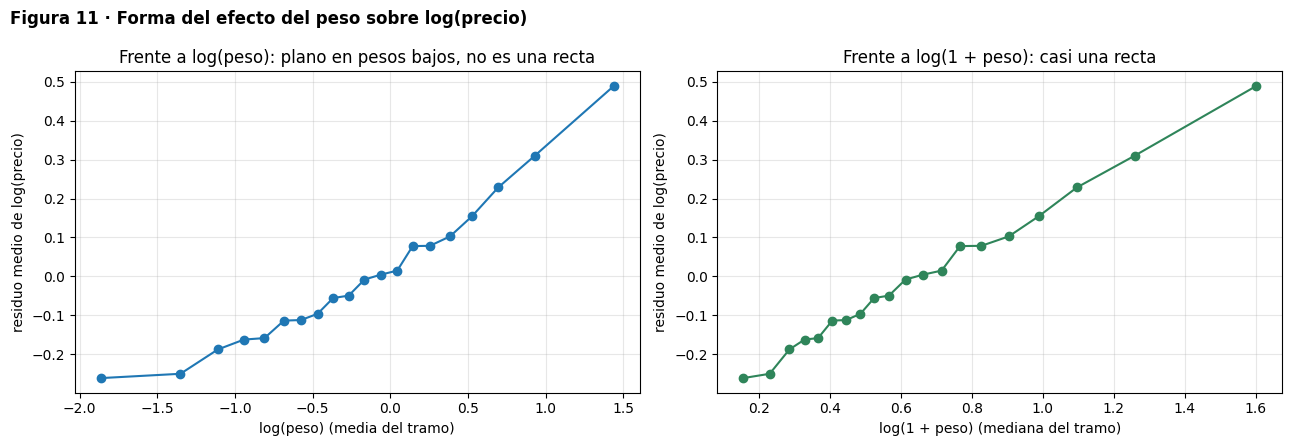

In [4]:
# Residuo de log(price) sin el peso
Xsin = variables(X, peso='crudo').drop(columns='peso')
prep = ColumnTransformer([('cat', OneHotEncoder(drop='first', sparse_output=False), CAT_SEL),
                          ('num', StandardScaler(), [c for c in NUMS if c != 'peso'])])
m = Pipeline([('prep', prep), ('model', LinearRegression())]).fit(Xsin, np.log(y))
res = np.log(y) - m.predict(Xsin)

tramos = pd.qcut(X.weight_kg, 20, labels=False)
forma = pd.DataFrame({'peso_mediano': X.weight_kg, 'log_peso': np.log(X.weight_kg), 'residuo': res}) \
          .groupby(tramos).agg(peso_mediano=('peso_mediano', 'median'), log_peso=('log_peso', 'mean'),
                               residuo_medio=('residuo', 'mean'))
print(forma.round(3).to_string())

# Correlación del residuo con cada transformación candidata del peso
cand = {'peso': X.weight_kg, 'log(peso)': np.log(X.weight_kg), 'log(1+peso)': np.log1p(X.weight_kg),
        'raíz(peso)': np.sqrt(X.weight_kg)}
print('\nCorrelación del residuo con cada transformación del peso:')
for k, v in cand.items():
    print(f'  {k:12s} {np.corrcoef(v, res)[0, 1]:.4f}')

# Figura 11
f, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(forma.log_peso, forma.residuo_medio, 'o-')
ax[0].set_xlabel('log(peso) (media del tramo)'); ax[0].set_ylabel('residuo medio de log(precio)')
ax[0].set_title('Frente a log(peso): plano en pesos bajos, no es una recta'); ax[0].grid(alpha=.3)
ax[1].plot(np.log1p(forma.peso_mediano), forma.residuo_medio, 'o-', c='#2f855a')
ax[1].set_xlabel('log(1 + peso) (mediana del tramo)'); ax[1].set_ylabel('residuo medio de log(precio)')
ax[1].set_title('Frente a log(1 + peso): casi una recta'); ax[1].grid(alpha=.3)
f.suptitle('Figura 11 · Forma del efecto del peso sobre log(precio)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## F3.2 Ingeniería de variables en el modelo lineal sobre log(precio)
Se parte de la referencia de la Fase 2 (regresión lineal en euros, conjunto reducido) y se cambia **un factor cada vez**. Todos los modelos sobre log(precio) llevan la corrección de Duan con residuos OOF (la que salió mejor en la Fase 2).
1. log(precio) con el peso sin transformar (lo que fallaba en F2.3).
2. log(precio) con log(peso).
3. log(precio) con log(1 + peso).
4. \+ log(1 + reviews) (reviews es muy asimétrica: hasta 1.578).
5. \+ splines cúbicas (5 nodos) sobre las numéricas, con Ridge (alpha = 1, sin ajustar todavía), para captar curvaturas que queden.

In [5]:
t_ini = time.time()
V_crudo = variables(X, peso='crudo')
V_log = variables(X, peso='log')
V_log1p = variables(X, peso='log1p')

evaluar('LIN|ref Fase 2 (euros)', lineal(), V_crudo, SPLITS)
evaluar('LOG|peso crudo', LogDuan(lineal()), V_crudo, SPLITS)
evaluar('LOG|log(peso)', LogDuan(lineal()), V_log, SPLITS)
evaluar('LOG|log(1+peso)', LogDuan(lineal()), V_log1p, SPLITS)
evaluar('LOG|log(1+peso) + log(1+reviews)', LogDuan(lineal()), XF, SPLITS)
evaluar('LOG|... + splines', LogDuan(lineal(splines=True, alpha=1.0)), XF, SPLITS)

PASOS = ['LIN|ref Fase 2 (euros)', 'LOG|peso crudo', 'LOG|log(peso)', 'LOG|log(1+peso)',
         'LOG|log(1+peso) + log(1+reviews)', 'LOG|... + splines']
print('\n===== Cada paso frente a la referencia de la Fase 2 =====')
tab_pasos = resumen(PASOS, 'LIN|ref Fase 2 (euros)'); mostrar(tab_pasos)

print('\n===== Cada paso frente al anterior (aporte de cada cambio) =====')
filas = []
for ant, act in zip(PASOS[2:-1], PASOS[3:]):
    dif = RES[act].rmse.to_numpy() - RES[ant].rmse.to_numpy()
    filas.append(dict(cambio=f'{ant}  ->  {act}', dif_media=dif.mean(), dif_std=dif.std(ddof=1),
                      folds_mejor=int((dif < 0).sum())))
print(pd.DataFrame(filas).set_index('cambio').round(3).to_string())
print(f'\nTiempo: {time.time() - t_ini:.0f} s')

  LIN|ref Fase 2 (euros): RMSE 54.054 (0 s)


  LOG|peso crudo: RMSE 101.565 (1 s)


  LOG|log(peso): RMSE 54.073 (1 s)


  LOG|log(1+peso): RMSE 52.945 (1 s)


  LOG|log(1+peso) + log(1+reviews): RMSE 52.656 (1 s)


  LOG|... + splines: RMSE 52.383 (2 s)

===== Cada paso frente a la referencia de la Fase 2 =====
                                     RMSE     std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                               
LIN|ref Fase 2 (euros)             54.054   5.046      0.000    0.000            0      38.744     173.603           50.0  34.784  0.5257  (referencia)
LOG|peso crudo                    101.565  55.232     47.511   54.420            0      40.692     404.667           70.8  36.959 -1.0862       EMPEORA
LOG|log(peso)                      54.073   4.885      0.019    0.854            8      38.576     174.484           50.5  34.601  0.5256        EMPATE
LOG|log(1+peso)                    52.945   4.792     -1.109    0.696           14      39.008     165.226           47.2  33.815  0.5447     

## F3.3 Comparación de modelos
Con las variables elegidas en F3.2 se comparan familias de modelos, todas con hiperparámetros por defecto (el ajuste es la Fase 4). Las de árboles son invariantes a transformaciones monótonas de las numéricas, así que el log del peso no les afecta.
- Ridge sobre log(precio) con splines (el mejor de F3.2).
- HistGradientBoosting en euros (la referencia de árboles de la Fase 2).
- HistGradientBoosting, RandomForest y GradientBoosting sobre log(precio) con Duan OOF.

In [6]:
t_ini = time.time()
evaluar('HGB|euros (Fase 2)', arboles('hgb'), XF, SPLITS)
evaluar('HGB|log + Duan', LogDuan(arboles('hgb')), XF, SPLITS)
evaluar('RF|log + Duan', LogDuan(arboles('rf', n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1)), XF, SPLITS)
evaluar('GBR|log + Duan', LogDuan(arboles('gbr')), XF, SPLITS)

MODELOS = ['LIN|ref Fase 2 (euros)', 'LOG|... + splines', 'HGB|euros (Fase 2)', 'HGB|log + Duan',
           'RF|log + Duan', 'GBR|log + Duan']
print('\n===== Comparación de modelos (referencia: lineal en euros de la Fase 2) =====')
tab_modelos = resumen(MODELOS, 'LIN|ref Fase 2 (euros)').sort_values('RMSE'); mostrar(tab_modelos)

print('\n===== Mejor modelo de árboles frente al lineal con splines =====')
mejor_arbol = tab_modelos.drop(['LIN|ref Fase 2 (euros)', 'LOG|... + splines']).RMSE.idxmin()
mostrar(resumen(['LOG|... + splines', mejor_arbol], 'LOG|... + splines'))
print(f'\nFinalistas para la Fase 4: LOG|... + splines y {mejor_arbol}')
print(f'Tiempo: {time.time() - t_ini:.0f} s')

  HGB|euros (Fase 2): RMSE 54.697 (505 s)


  HGB|log + Duan: RMSE 54.083 (1487 s)


  RF|log + Duan: RMSE 55.132 (124 s)


  GBR|log + Duan: RMSE 53.765 (78 s)

===== Comparación de modelos (referencia: lineal en euros de la Fase 2) =====
                          RMSE    std  dif_media  dif_std  folds_mejor  RMSE_le300  RMSE_gt300  pct_MSE_gt300     MAE      R2     veredicto
variante                                                                                                                                   
LOG|... + splines       52.383  4.875     -1.671    0.752           15      38.390     164.434           47.7  33.354  0.5544        MEJORA
GBR|log + Duan          53.765  4.908     -0.289    0.840           11      38.716     171.921           49.5  34.374  0.5308        EMPATE
LIN|ref Fase 2 (euros)  54.054  5.046      0.000    0.000            0      38.744     173.603           50.0  34.784  0.5257  (referencia)
HGB|log + Duan          54.083  4.781      0.029    0.881            8      40.128     167.601           46.5  34.967  0.5250        EMPATE
HGB|euros (Fase 2)      54.697  4.677      0

## F3.4 Figura 12: RMSE de cada modelo (media ± desviación entre folds)

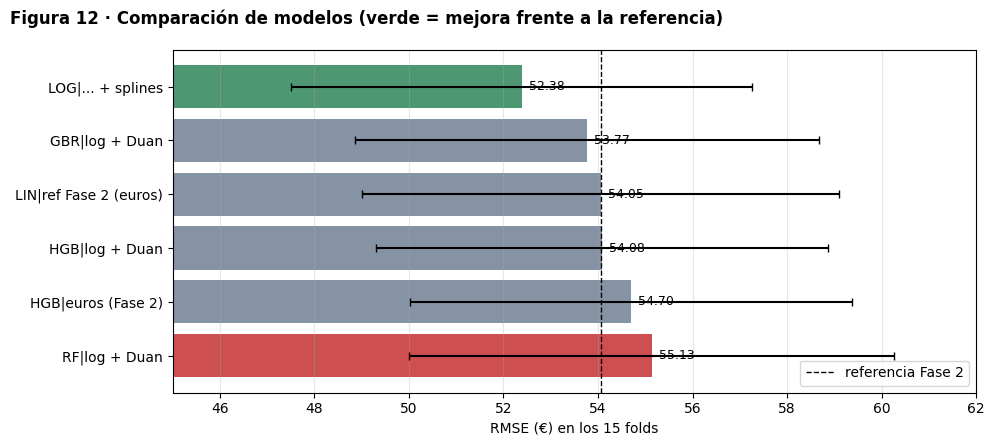

In [7]:
t = tab_modelos.sort_values('RMSE', ascending=False)
f, ax = plt.subplots(figsize=(10, 4.5))
col = ['#2f855a' if v == 'MEJORA' else ('#c53030' if v == 'EMPEORA' else '#718096') for v in t.veredicto]
ax.barh(t.index, t.RMSE, xerr=t['std'], color=col, alpha=.85, capsize=3)
ax.axvline(RES['LIN|ref Fase 2 (euros)'].rmse.mean(), c='k', lw=1, ls='--', label='referencia Fase 2')
for i, v in enumerate(t.RMSE):
    ax.text(v + 0.15, i, f'{v:.2f}', va='center', fontsize=9)
ax.set_xlim(45, 62); ax.set_xlabel('RMSE (€) en los 15 folds'); ax.grid(alpha=.3, axis='x'); ax.legend(loc='lower right')
f.suptitle('Figura 12 · Comparación de modelos (verde = mejora frente a la referencia)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()